## Baseline Logistic Regression (next-day prediction)
Uses `src/prep_data.py` and `src/evaluate_model.py` to prep data and evaluate each model.

**Task:** use one day's weather to predict whether the **next** day is an ozone day.

In [1]:
import sys; sys.path.append("..")
import pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from src.prep_data import get_splits, make_model_pipeline
from src.evaluate_model import best_threshold, evaluate, full_report, time_series_cv

### 1. Load data, build next-day target, clean, then split chronologically
Days with more than 50% of features missing are dropped. Remaining gaps are imputed inside the model pipeline, fit on training data only.

In [2]:
data = get_splits()
X_train, y_train = data["X_train"], data["y_train"]
X_val,   y_val   = data["X_val"],   data["y_val"]
X_test,  y_test  = data["X_test"],  data["y_test"]
features = data["features"]

Next-day target: dropped 9 rows with no following calendar day
Dropped 172 rows (6.8%) with >50% features missing (6 were positive); 2353 rows and 72 features remain
Remaining cells missing (to be imputed): 3.2%
train  1647 rows  1998-01-01 -> 2003-01-22  positives: 125  rate: 0.076
val     353 rows  2003-01-23 -> 2004-01-12  positives:  18  rate: 0.051
test    353 rows  2004-01-13 -> 2004-12-30  positives:  11  rate: 0.031


### 2. Fit the model
Median imputation, then standardization, then logistic regression. Since ozone days are rare, use `class_weight="balanced"` to compensate.

In [3]:
def make_logreg():
    return make_model_pipeline(LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42))

model = make_logreg().fit(X_train, y_train)

p_train = model.predict_proba(X_train)[:, 1]
p_val   = model.predict_proba(X_val)[:, 1]
evaluate("train", y_train, p_train)
evaluate("val  ", y_val, p_val);

train: ROC-AUC=0.930  PR-AUC=0.525 (random=0.076)  @0.50: P=0.305 R=0.912 F1=0.457
val  : ROC-AUC=0.796  PR-AUC=0.383 (random=0.051)  @0.50: P=0.145 R=0.667 F1=0.238


### 3. Choose the decision threshold on validation

In [4]:
thr, f1 = best_threshold(y_val, p_val)
print(f"Best validation threshold: {thr:.3f} (F1={f1:.3f})")
results_val = evaluate("val  ", y_val, p_val, thr)

Best validation threshold: 0.951 (F1=0.417)
val  : ROC-AUC=0.796  PR-AUC=0.383 (random=0.051)  @0.95: P=0.833 R=0.278 F1=0.417


### 4. Test-set evaluation
The test year (2004) has few ozone days, so treat these numbers as noisy.

In [5]:
p_test = model.predict_proba(X_test)[:, 1]
results_logreg = evaluate("test ", y_test, p_test, thr)
full_report(y_test, p_test, thr)

test : ROC-AUC=0.947  PR-AUC=0.381 (random=0.031)  @0.95: P=0.444 R=0.364 F1=0.400
Confusion matrix (rows=actual, cols=predicted):
 [[337   5]
 [  7   4]]
              precision    recall  f1-score   support

           0      0.980     0.985     0.983       342
           1      0.444     0.364     0.400        11

    accuracy                          0.966       353
   macro avg      0.712     0.675     0.691       353
weighted avg      0.963     0.966     0.964       353



### 5. Time-series cross-validation (train + val)
Use `time_series_cv` from `src/evaluate_model.py`. This is the main number for comparing models.

In [6]:
X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val])
cv = time_series_cv(make_logreg(), X_dev, y_dev, n_splits=5)
display(cv); print(cv[["roc_auc", "pr_auc"]].agg(["mean", "std"]).round(3))

,fold,n_test,positives,roc_auc,pr_auc
0,1,333,29,0.800930,0.226761
1,2,333,39,0.820949,0.413190
2,3,333,16,0.873817,0.241073
3,4,333,9,0.900892,0.335769
4,5,333,18,0.784832,0.381329


      roc_auc  pr_auc
mean    0.836   0.320
std     0.049   0.083


### 6. Largest coefficients

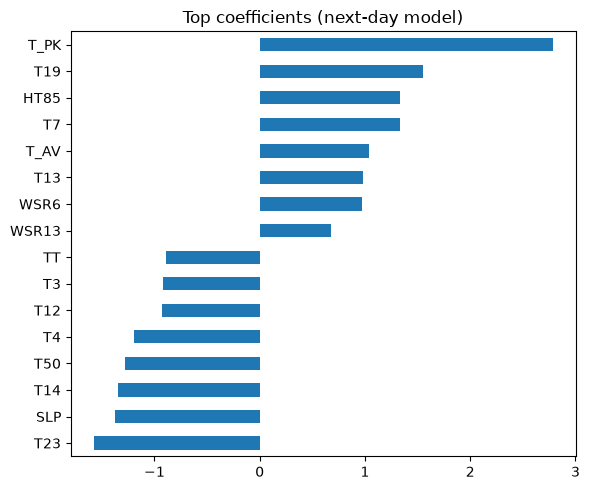

In [7]:
coefs = pd.Series(model.named_steps["clf"].coef_[0], index=features).sort_values()
pd.concat([coefs.head(8), coefs.tail(8)]).plot.barh(figsize=(6, 5)); plt.title("Top coefficients (next-day model)"); plt.tight_layout(); plt.show()

### 7. How much harder is next-day than same-day?
Same pipeline and CV on three setups: same-day (classifying a day from its own weather), next-day, and next-day with today's ozone label added as a feature.

In [8]:
rows = []
for label, kwargs in [("same-day", dict(horizon="same_day")),
                      ("next-day", dict(horizon="next_day")),
                      ("next-day + today's class", dict(horizon="next_day", include_today_class=True))]:
    d = get_splits(verbose=False, **kwargs)
    Xd = pd.concat([d["X_train"], d["X_val"]]); yd = pd.concat([d["y_train"], d["y_val"]])
    r = time_series_cv(make_logreg(), Xd, yd, n_splits=5)
    rows.append({"setup": label, "cv_roc_auc": r.roc_auc.mean(), "cv_pr_auc": r.pr_auc.mean(),
                 "pr_auc_std": r.pr_auc.std(), "random_pr_auc": yd.mean()})
horizons = pd.DataFrame(rows).round(3)
horizons

,setup,cv_roc_auc,cv_pr_auc,pr_auc_std,random_pr_auc
0,same-day,0.886,0.343,0.117,0.071
1,next-day,0.836,0.320,0.083,0.072
2,next-day + today's class,0.833,0.323,0.090,0.072


## Summary

**Setup:** Next-day prediction: each day's weather predicts whether the following day is an ozone day.
9 rows with no following calendar day and 172 mostly-empty days (>50% features missing, 6 positives) were dropped,
leaving 2,353 rows and all 72 features. The remaining 3.2% of missing cells are median-imputed inside the pipeline
(fit on train only). Data was split chronologically 70/15/15 (test = 2004, 11 ozone days).

**Model:** Median imputation, standardization, logistic regression with balanced class weights. This is the baseline.

**Results:**
| Split | ROC-AUC | PR-AUC | Random PR-AUC |
|---|---|---|---|
| Train | 0.930 | 0.525 | 0.076 |
| Validation | 0.796 | 0.383 | 0.051 |
| Test | 0.947 | 0.381 | 0.031 |
| 5-fold time-series CV | 0.836 ± 0.049 | 0.320 ± 0.083 | ~0.07 |

At the validation-chosen threshold (0.95), test precision = 0.44, recall = 0.36 (4 of 11 ozone days caught, 5 false alarms).

**Next-day vs same-day (CV, same pipeline):**
| Setup | ROC-AUC | PR-AUC |
|---|---|---|
| Same-day | 0.886 | 0.343 |
| Next-day | 0.836 | 0.320 |
| Next-day + today's ozone label | 0.833 | 0.323 |

Next-day forecasting is only slightly harder than same-day classification, so the proposal's main goal is feasible.
Adding today's ozone label does not help a linear model.

**Caveats:**
- The train/validation gap (ROC-AUC 0.93 vs 0.80) suggests overfitting on 72 correlated features; tuning regularization (`C`) may help.
- The best-F1 threshold (0.95) was chosen on only 18 validation positives and favors precision over recall. For a warning system, a lower threshold with higher recall may be preferable.
- With 11 test positives, test metrics are still noisy; CV is the main comparison.